### <b>7강 범주 비교 그래프 - countplot · barplot · stripplot · pointplot</b>

* <b>countplot</b>은 범주별 개수를, <b>barplot</b>은 범주별 평균을 Seaborn이 직접 계산해서 막대로 그린다. value_counts·groupby를 따로 하지 않아도 된다.
* barplot 막대 끝의 검은 선(<b>오차 막대</b>)은 그 평균이 얼마나 흔들릴 수 있는지를 보여 준다. <b>errorbar=</b>로 신뢰구간·표준편차·없음을 고른다.
* <b>stripplot</b>은 평균 뒤에 숨은 한 명 한 명을 점으로 꺼내 보여 주고, <b>pointplot</b>은 평균을 점과 선으로 이어 요일처럼 순서가 있는 범주의 흐름을 보여 준다.

* 첫 코드 셀은 6강에서 정한 <b>설정 셀</b> 그대로다.
  * <b>sns.set_theme(...)</b>에 한글 폰트와 마이너스 설정을 함께 넘긴다. 그래프 글자가 깨지면 이 셀을 다시 실행한다.

In [1]:
# keep
import platform
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if platform.system() == 'Windows':
    font_name = 'Malgun Gothic'
else:
    font_name = 'AppleGothic'
sns.set_theme(style='whitegrid', font=font_name, rc={'axes.unicode_minus': False})

* 오늘은 두 파일을 모두 쓴다. 2강과 같은 방법으로 읽는다.
  * <b>students</b>: 학생 300명의 생활 습관 설문(가상), 학생 1명 = 1행
  * <b>cafe</b>: 캠퍼스 카페 1년 일별 판매(가상), 하루 = 1행
* 범주를 놓을 순서 리스트도 미리 만들어 둔다. 6강의 major_order, 2강의 weekday_order·period_order와 같다.

In [2]:
# keep
students = pd.read_csv('../data/students.csv')
cafe = pd.read_csv('../data/cafe_sales.csv', parse_dates=['date'])
print(students.shape, cafe.shape)

major_order = ['공학', '자연과학', '사회과학', '인문', '예체능']
weekday_order = ['월', '화', '수', '목', '금', '토', '일']
period_order = ['1학기', '여름방학', '2학기', '겨울방학']

(300, 12) (365, 14)


#### <b>1) 전공별·주거 형태별 학생 수</b>

* 4강에서는 전공별 학생 수 막대를 두 단계로 그렸다.
  * <b>value_counts()</b>로 전공별 학생 수 표(major_count)를 만들고, <b>ax.bar</b>에 index와 values를 넘겼다.
* <b>sns.countplot(data=표, x='범주 열')</b>: 범주마다 행이 몇 개인지 세서 막대로 그린다. 세는 일을 Seaborn이 한다.
* 두 방법을 1×2 칸에 나란히 그려 비교한다.

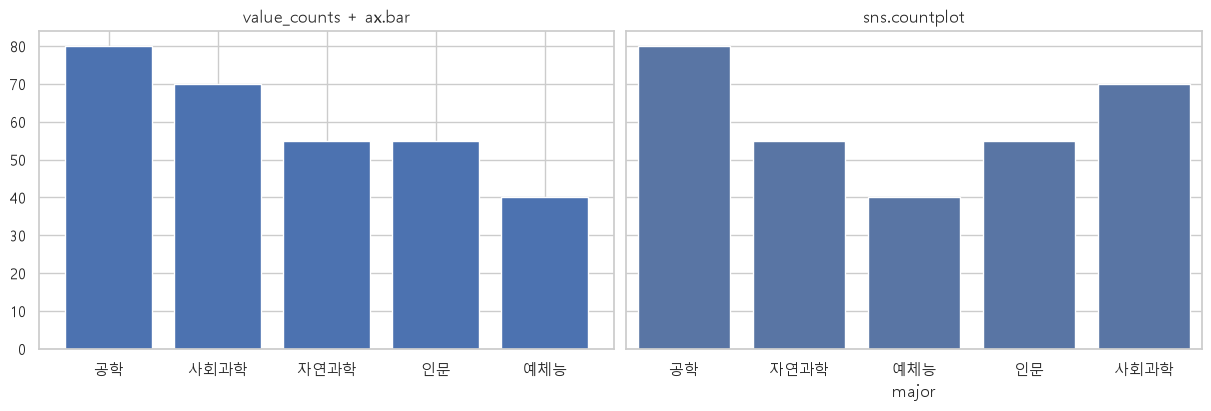

In [3]:
major_count = students['major'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')
axes[0].bar(major_count.index, major_count.values)
axes[0].set_title('value_counts + ax.bar')
sns.countplot(data=students, x='major', ax=axes[1])
axes[1].set_title('sns.countplot')
plt.show()

* 막대 높이는 같다. 공학 80, 사회과학 70, 자연과학·인문 55, 예체능 40명이다.
  * 자연과학과 인문은 둘 다 55명으로 높이가 같다. 둘 사이의 순위는 없다.
* 막대 순서가 다르다.
  * 왼쪽은 value_counts가 많은 순서로 정렬한 순서다.
  * 오른쪽 countplot은 표에 <b>처음 나온 순서</b>(공학·자연과학·예체능·인문·사회과학)로 놓는다. 가나다순도, 많은 순서도 아니다.
* countplot은 y축 이름 'count'와 x축 이름 'major'를 자동으로 단다.
* <b>order=</b>: 범주를 놓을 순서 리스트. 많은 순서로 놓으려면 major_count.index(value_counts 결과의 순서)를 그대로 넘긴다.

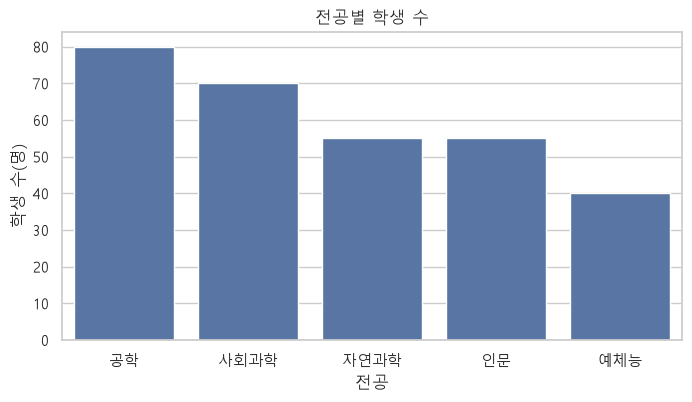

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=students, x='major', order=major_count.index, ax=ax)
ax.set_title('전공별 학생 수')
ax.set_xlabel('전공')
ax.set_ylabel('학생 수(명)')
plt.show()

* 이제 4강 막대와 같은 순서다. 공학이 가장 많고 예체능이 가장 적다.
* <b>hue='housing'</b>: 6강처럼 색으로 집단을 나눈다. 전공 막대 하나가 기숙사·자취·통학 막대 세 개로 나란히 갈라진다.
  * countplot은 hue로 나눈 막대를 기본으로 옆에 나란히 놓는다.
  * 주거 형태 순서는 표에 처음 나온 순서(기숙사·자취·통학)다. 바꾸려면 <b>hue_order=</b>에 리스트를 넘긴다.

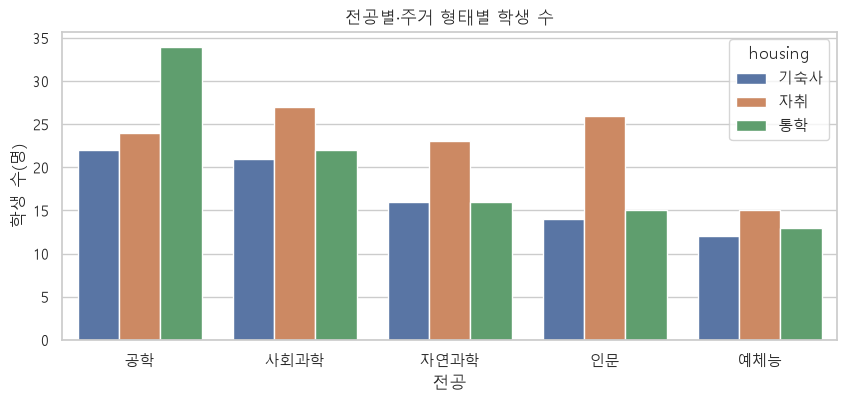

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(data=students, x='major', hue='housing', order=major_count.index, ax=ax)
ax.set_title('전공별·주거 형태별 학생 수')
ax.set_xlabel('전공')
ax.set_ylabel('학생 수(명)')
plt.show()

* 그래프에서 읽을 것
  * 공학은 통학 막대(34명)가 가장 높다. 다른 네 전공은 모두 자취 막대가 가장 높다.
  * 막대가 15개로 늘어 숫자를 정확히 읽기는 어렵다. 정확한 숫자가 필요하면 표로 확인한다.
* 2강의 groupby로 같은 숫자를 표로 볼 수 있다. <b>size()</b>는 묶음마다 행 수를 세고, <b>unstack()</b>은 안쪽 묶음(housing)을 열로 펼친다.

In [6]:
students.groupby(['major', 'housing']).size().unstack().reindex(major_count.index)

housing,기숙사,자취,통학
major,,,
공학,22,24,34
사회과학,21,27,22
자연과학,16,23,16
인문,14,26,15
예체능,12,15,13


#### <b>2) 전공별 평균 시험 점수</b>

* 개수 대신 평균을 비교한다. 먼저 2강 방법으로 전공별 평균 시험 점수 표를 만든다.
  * 2강의 study_by_major와 같은 방법이다. 열만 exam_score로 바꾸고, 순서는 reindex(major_order)로 맞춘다.

In [7]:
score_by_major = students.groupby('major')['exam_score'].mean().round(2).reindex(major_order)
score_by_major

major
공학      79.62
자연과학    74.07
사회과학    72.90
인문      71.09
예체능     66.50
Name: exam_score, dtype: float64

* 공학 79.62 → 자연과학 74.07 → 사회과학 72.90 → 인문 71.09 → 예체능 66.50점. 공부 시간 순서(major_order)와 같은 순서로 내려간다.
* <b>sns.barplot(data=표, x='범주 열', y='수치 열')</b>: 범주마다 y 열의 <b>평균</b>을 계산해서 막대 높이로 그린다.
  * groupby·mean을 하지 않고 원래 표(students)를 그대로 넘긴다.
  * 순서는 countplot처럼 <b>order=</b>로 정한다.
* 막대 높이가 위 표와 같은지 확인한다. 6강처럼 <b>ax.patches</b>로 막대를 꺼내 높이를 출력한다.

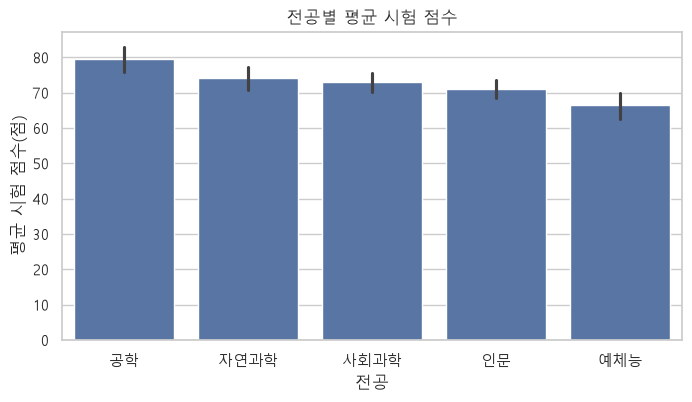

[79.62, 74.07, 72.9, 71.09, 66.5]


In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=students, x='major', y='exam_score', order=major_order, ax=ax)
ax.set_title('전공별 평균 시험 점수')
ax.set_xlabel('전공')
ax.set_ylabel('평균 시험 점수(점)')
plt.show()

print([round(float(p.get_height()), 2) for p in ax.patches])

* 막대 높이가 score_by_major와 같다. barplot은 groupby 평균을 대신 계산했다.
* 막대 위에 검은 세로선이 있다. 이것이 <b>오차 막대</b>(error bar)다.
  * 기본값은 <b>95% 신뢰구간</b>이다. 전체 학생의 평균이 있을 법한 범위다. 데이터를 다시 뽑았을 때 평균이 얼마나 흔들리는지로 구한다.
  * 선이 길수록 평균이 더 흔들릴 수 있다. 막대 높이 차이가 선 길이보다 작으면 그 차이는 조심해서 읽는다.
* 막대는 0에서 시작한다(4강). 66~80점 차이가 막대로는 작아 보이는 것이 정상이다.

#### <b>3) errorbar 세 가지로 바꿔 보기</b>

* barplot은 신뢰구간을 <b>부트스트랩</b>으로 구한다.
  * 부트스트랩: 가진 데이터에서 같은 학생이 여러 번 뽑힐 수 있게(복원 추출) 원래 학생 수만큼 무작위로 다시 뽑아 평균을 내는 일을 여러 번(기본 1000번) 되풀이해서, 평균이 흔들리는 범위를 구하는 방법이다.
  * 무작위로 뽑으므로 실행할 때마다 선 끝이 조금씩 달라진다.
* 같은 그래프를 두 번 그리고 공학 오차 막대의 아래·위 끝을 출력해 본다.
  * <b>ax.lines</b>는 칸에 그려진 선 목록이다. 첫 번째 선이 공학 오차 막대다.
  * 그래프 확인이 목적이 아니므로 <b>plt.close(fig)</b>로 화면에 그리지 않고 닫는다.

In [9]:
for i in range(2):
    fig, ax = plt.subplots()
    sns.barplot(data=students, x='major', y='exam_score', order=major_order, ax=ax)
    print('seed 없음:', ax.lines[0].get_ydata().round(2))
    plt.close(fig)

for i in range(2):
    fig, ax = plt.subplots()
    sns.barplot(data=students, x='major', y='exam_score', order=major_order, seed=0, ax=ax)
    print('seed=0  :', ax.lines[0].get_ydata().round(2))
    plt.close(fig)

seed 없음: [75.69 83.1 ]
seed 없음: [75.89 83.45]
seed=0  : [75.9  83.08]


seed=0  : [75.9  83.08]


* seed가 없으면 두 번의 끝 값이 1점 안쪽으로 조금 다르다. 대략 76~83점 사이다.
* <b>seed=0</b>처럼 숫자를 정해 주면 무작위 뽑기가 매번 같아져서 끝 값도 같다. 보고서처럼 같은 그림을 다시 만들어야 할 때 쓴다. 숫자는 아무것이나 괜찮다.
* <b>errorbar=</b>로 선이 보여 줄 것을 바꾼다.
  * <b>('ci', 95)</b>(기본값): 95% 신뢰구간. 평균이 얼마나 흔들릴 수 있는지
  * <b>'sd'</b>: 표준편차. 평균 ± 표준편차 1개만큼. 학생 한 명 한 명의 점수가 평균에서 얼마나 퍼져 있는지
  * <b>None</b>: 선을 그리지 않음. 따옴표 없이 쓴다.
* 세 가지를 1×3 칸에 나란히 그린다. sharey=True로 세 칸의 y축 눈금을 맞춘다.

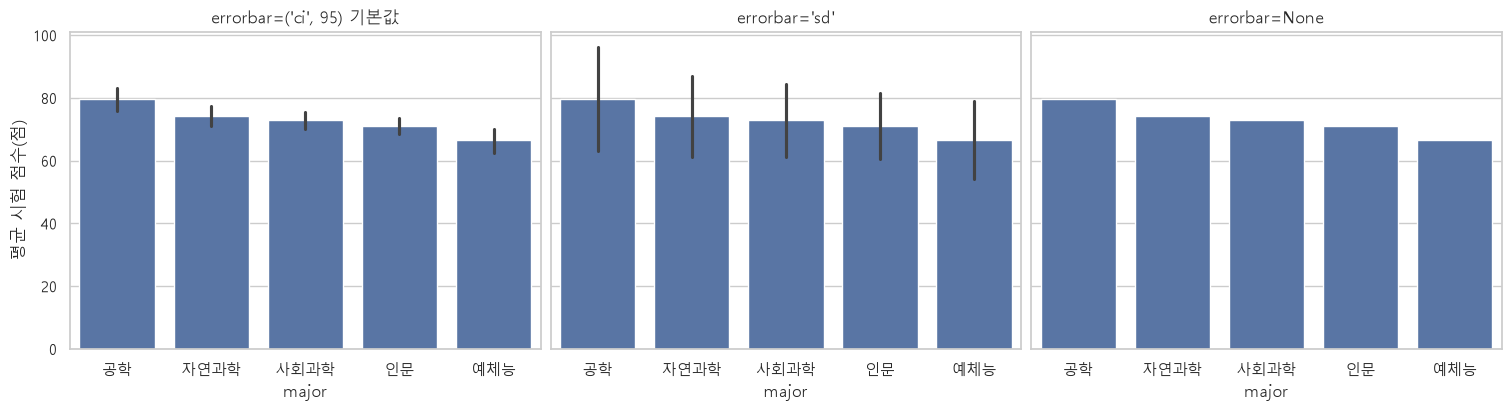

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, layout='constrained')
sns.barplot(data=students, x='major', y='exam_score', order=major_order, ax=axes[0])
axes[0].set_title("errorbar=('ci', 95) 기본값")
sns.barplot(data=students, x='major', y='exam_score', order=major_order, errorbar='sd', ax=axes[1])
axes[1].set_title("errorbar='sd'")
sns.barplot(data=students, x='major', y='exam_score', order=major_order, errorbar=None, ax=axes[2])
axes[2].set_title('errorbar=None')
axes[0].set_ylabel('평균 시험 점수(점)')
plt.show()

* 그래프에서 읽을 것
  * 막대 높이는 세 칸이 모두 같다. 바뀐 것은 선뿐이다.
  * 'sd'(가운데) 선이 신뢰구간(왼쪽)보다 훨씬 길다. 공학 선은 약 63~96점까지 뻗는다. 학생 한 명 한 명의 점수는 평균보다 훨씬 넓게 퍼져 있다.
  * 신뢰구간(왼쪽)은 공학·예체능 선이 길고, 사회과학·인문 선이 짧다.
* 선 길이는 무엇으로 정해질까? 전공별 학생 수(count)와 표준편차(std)를 함께 본다.

In [11]:
students.groupby('major')['exam_score'].agg(['count', 'std']).round(2).reindex(major_order)

,count,std
major,,
공학,80,16.67
자연과학,55,12.77
사회과학,70,11.60
인문,55,10.46
예체능,40,12.37


* 표준편차는 공학 16.67점이 가장 크고 인문 10.46점이 가장 작다. 'sd' 선 길이가 이 순서를 따른다.
* 신뢰구간 선 길이는 <b>학생 수와 퍼짐 둘 다</b>에 달려 있다.
  * 예체능은 40명으로 학생이 가장 적어서 선이 길다.
  * 공학은 80명으로 가장 많지만 점수가 가장 넓게 퍼져 있어서 선이 길다.
  * 사회과학(70명)은 학생이 많고 퍼짐이 작아 선이 짧다. 인문은 55명이지만 퍼짐이 가장 작아 선이 짧다.
* 같은 퍼짐이라면 학생이 많을수록 평균은 덜 흔들린다. 표준편차는 학생 수가 늘어도 줄지 않는다.
* 그래프에 오차 막대를 넣을 때는 무엇을 그렸는지(신뢰구간인지 표준편차인지) 제목이나 설명에 적는다.

#### <b>4) 박스플롯 + stripplot 겹치기</b>

* 평균 막대는 한 전공을 숫자 하나로 줄인다. 6강 박스플롯은 다섯 값으로 줄인다. 이번에는 줄이지 않고 학생 한 명 한 명을 점으로 찍는다.
* <b>sns.stripplot(data=표, x='범주 열', y='수치 열')</b>: 범주마다 한 줄로 점을 찍는다. 학생 1명 = 점 1개다.
  * <b>jitter</b>: 점을 좌우로 조금씩 흩뿌리는 정도. 기본값 True로 흩뿌린다. False면 한 줄에 겹쳐 찍힌다.
  * 흩뿌리는 위치는 무작위라서 실행할 때마다 점의 좌우 위치가 조금 달라진다. 세로 위치(값)는 그대로다.
* jitter=False와 기본값을 1×2로 비교한다. 6강의 공부 시간을 그대로 쓴다.

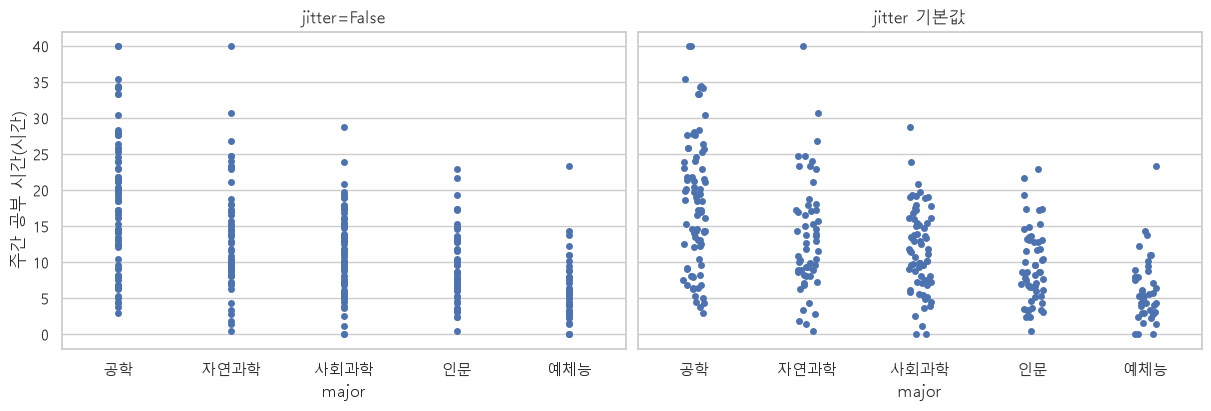

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')
sns.stripplot(data=students, x='major', y='study_hours', order=major_order, jitter=False, ax=axes[0])
axes[0].set_title('jitter=False')
sns.stripplot(data=students, x='major', y='study_hours', order=major_order, ax=axes[1])
axes[1].set_title('jitter 기본값')
axes[0].set_ylabel('주간 공부 시간(시간)')
plt.show()

* jitter=False(왼쪽)는 점이 한 줄로 겹쳐서 몇 명이 있는지 알기 어렵다.
* 기본값(오른쪽)은 점이 퍼져서 몰린 곳이 보인다. 예체능은 점 40개 중 33개가 10시간 아래에 몰려 있다.
* 6강 박스플롯 위에 점을 겹친다. 같은 ax에 차례로 그리면 된다.
  * <b>showfliers=False</b>: 박스플롯의 이상치 점을 그리지 않는다. 모든 학생이 strip 점으로 찍히므로, 빼지 않으면 이상치가 두 번 찍힌다.
  * strip 점은 <b>color='black'</b>, <b>size=3</b>(점 크기, 기본 5), <b>alpha=0.5</b>로 작고 흐리게 해서 상자를 가리지 않게 한다.

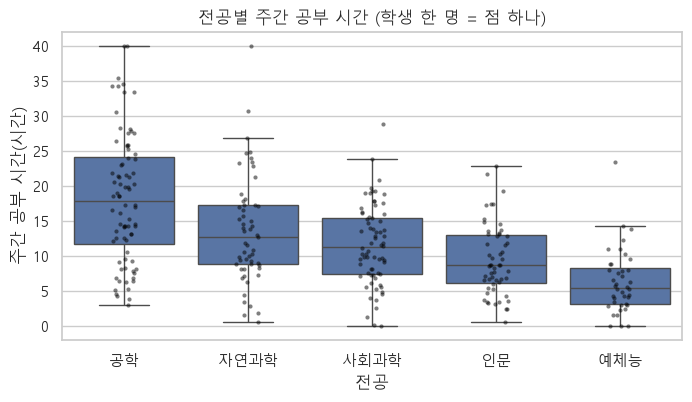

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=students, x='major', y='study_hours', order=major_order, showfliers=False, ax=ax)
sns.stripplot(data=students, x='major', y='study_hours', order=major_order,
              color='black', size=3, alpha=0.5, ax=ax)
ax.set_title('전공별 주간 공부 시간 (학생 한 명 = 점 하나)')
ax.set_xlabel('전공')
ax.set_ylabel('주간 공부 시간(시간)')
plt.show()

* 그래프에서 읽을 것
  * 상자는 가운데 50%, 점은 학생 한 명이다. 공학 80개, 예체능 40개처럼 전공마다 점 개수가 다르다. 상자만 볼 때는 안 보이던 학생 수 차이가 보인다.
  * 공학·자연과학에는 40시간 점이 맨 위에 있다. 6강에서 자연과학 40시간은 이상치 점, 공학 40시간은 수염 안이었다.
  * 상자 안에서도 점이 고르게 퍼진 전공과 한쪽에 몰린 전공이 있다. 상자만으로는 이 차이가 안 보인다.
* 학생이 수백 명을 넘어 점이 너무 빽빽하면 stripplot 대신 박스플롯·바이올린 플롯만 쓴다.

#### <b>5) 요일별 평균 손님 수 pointplot</b>

* <b>sns.pointplot(data=표, x='범주 열', y='수치 열')</b>: barplot처럼 범주마다 평균을 계산한다. 막대 대신 <b>점</b>을 찍고 점끼리 <b>선</b>으로 잇는다.
  * 점 위아래 세로선은 barplot과 같은 95% 신뢰구간이다.
  * 요일처럼 순서가 있는 범주에서 오르내리는 흐름을 보기 좋다.
* 먼저 order 없이 그리고, 다음에 weekday_order를 넘겨 비교한다.

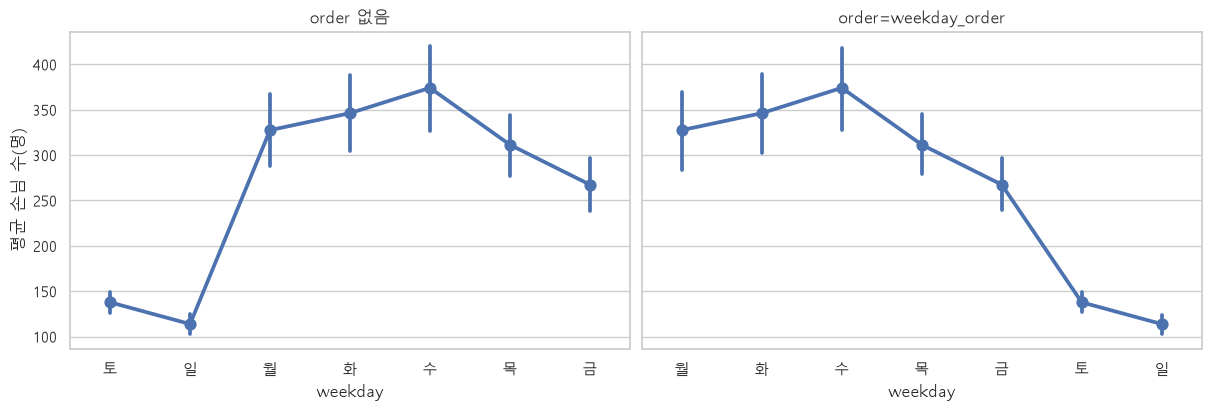

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')
sns.pointplot(data=cafe, x='weekday', y='customers', ax=axes[0])
axes[0].set_title('order 없음')
sns.pointplot(data=cafe, x='weekday', y='customers', order=weekday_order, ax=axes[1])
axes[1].set_title('order=weekday_order')
axes[0].set_ylabel('평균 손님 수(명)')
plt.show()

* order가 없으면(왼쪽) 토요일부터 시작한다. 데이터 첫날 2025-03-01이 토요일이라 표에 처음 나온 순서로 놓였다.
  * 선이 토·일에서 낮게 시작해 올라갔다가 다시 내려가서, 주말에 떨어지는 모양이 둘로 쪼개져 보인다.
* order=weekday_order(오른쪽)는 월~일 순서다. 수요일이 가장 높고, 금요일부터 내려가 토·일에 크게 떨어진다.
* 점의 높이가 2강 customers_by_weekday와 같은지 확인한다. ax.lines의 첫 번째 선이 점을 이은 선이다.
  * 이 평균에는 2강에서 본 휴무일의 0이 섞여 있다. groupby도 pointplot도 같은 365일로 계산한다.

In [15]:
customers_by_weekday = cafe.groupby('weekday')['customers'].mean().round(2).reindex(weekday_order)
print(customers_by_weekday.values)
print(axes[1].lines[0].get_ydata().round(2))

[327.5  346.21 374.1  311.38 267.42 137.74 113.79]
[327.5  346.21 374.1  311.38 267.42 137.74 113.79]


* 두 줄이 같다. 수요일 374.10명, 일요일 113.79명이다.
* pointplot의 y축은 0에서 시작하지 않는다(약 90~430). 점은 길이가 아니라 위치로 읽기 때문이다. 막대(barplot)는 0에서 시작해야 한다는 4강 규칙과 다르다.
* <b>hue='period'</b>: 학사 기간마다 색이 다른 점과 선을 그린다.
  * <b>hue_order=period_order</b>: 범례와 색을 1학기 → 여름방학 → 2학기 → 겨울방학 순서로 놓는다. 이 데이터는 처음 나온 순서도 같지만, 순서를 분명히 하려고 넘긴다.
  * <b>dodge=True</b>: 같은 요일의 점을 좌우로 조금 벌려 놓는다. 넣지 않으면 네 기간의 신뢰구간 선이 한 자리에 겹친다.

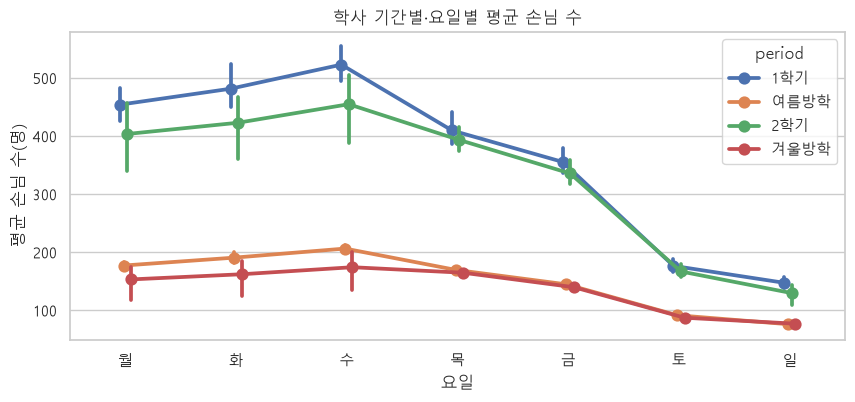

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.pointplot(data=cafe, x='weekday', y='customers', order=weekday_order,
              hue='period', hue_order=period_order, dodge=True, ax=ax)
ax.set_title('학사 기간별·요일별 평균 손님 수')
ax.set_xlabel('요일')
ax.set_ylabel('평균 손님 수(명)')
plt.show()

* 그래프에서 읽을 것
  * 학기(1학기·2학기) 선은 위에, 방학(여름방학·겨울방학) 선은 아래에 있다. 2강의 기간별 평균에서 본 차이다.
  * 네 기간 모두 수요일이 가장 높고 일요일이 가장 낮다. 가장 높은 점은 1학기 수요일 523명이다.
  * 방학 두 선은 목요일부터 거의 겹친다. 주말에는 학기 선도 크게 내려와 방학 선과 가까워진다.
  * 2학기 월·화·수 세로선이 유난히 길다. 추석 휴무일(10/6~10/8)의 0이 섞여 평균이 흔들리기 때문이다. 겨울방학 월·화·수 세로선도 설 휴무일(2/16~2/18) 때문에 같은 기간 다른 요일보다 길다.
* 같은 평균을 barplot으로 그리면 막대 28개가 된다. 집단이 여러 개이고 범주에 순서가 있으면 pointplot의 선이 흐름을 읽기 쉽다.
* 오늘 정리: <b>countplot</b>은 개수, <b>barplot</b>은 평균과 그 흔들림, <b>stripplot</b>은 개별 값, <b>pointplot</b>은 평균의 흐름을 보여 준다.